# 10 - Handwriting Recognition (digits): from k-NN to a CNN, and what happens off the textbook
**Topic:** Computer Vision  |  **Reference:** "Handwriting Recognition with Python" (amanxai.com, Oct 2020)

**Question.** Can a model read handwritten digits, and does it still work when the writing is not as tidy as the benchmark?

**Reference method:** k-nearest-neighbours on 32x32 black-and-white images flattened into 1,024-long vectors (a small teaching data set that is not publicly downloadable).
**What I do:** use the standard **MNIST** data (60,000 + 10,000 images), reproduce the reference idea (k-NN on raw pixels), add a logistic regression and a small **CNN** (PyTorch, CPU), study the **mistakes**, check **confidence calibration**, and then test **robustness**: rotated, shifted, noisy, thicker/thinner and inverted digits, with and without training on augmented data. A model that scores 99% on MNIST but fails on slightly different writing is not a handwriting reader.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, accuracy_score
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(8)
os.makedirs("model", exist_ok=True)
tr_ds = datasets.MNIST("../_data/mnist", train=True, download=True); te_ds = datasets.MNIST("../_data/mnist", train=False, download=True)
Xall = tr_ds.data.numpy().astype(np.float32) / 255; yall = tr_ds.targets.numpy()
Xte = te_ds.data.numpy().astype(np.float32) / 255; yte = te_ds.targets.numpy()
# hold out 5,000 training images as a validation set; the 10,000 test images are used once at the end
rng = np.random.RandomState(0); perm = rng.permutation(len(Xall)); va_i, tr_i = perm[:5000], perm[5000:]
Xtr, ytr, Xva, yva = Xall[tr_i], yall[tr_i], Xall[va_i], yall[va_i]
print("train", Xtr.shape, "| validation", Xva.shape, "| test", Xte.shape, "| pixel range", Xtr.min(), Xtr.max())

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  2%|▏         | 197k/9.91M [00:00<00:06, 1.51MB/s]

 11%|█         | 1.11M/9.91M [00:00<00:01, 5.52MB/s]

 25%|██▌       | 2.52M/9.91M [00:00<00:00, 9.16MB/s]

 35%|███▌      | 3.51M/9.91M [00:00<00:00, 8.75MB/s]

 59%|█████▊    | 5.80M/9.91M [00:00<00:00, 13.2MB/s]

... (8 outputs left out)

100%|██████████| 1.65M/1.65M [00:00<00:00, 5.11MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 6.02MB/s]

train (55000, 28, 28) | validation (5000, 28, 28) | test (10000, 28, 28) | pixel range 0.0 1.0


## 2. Look at the data first

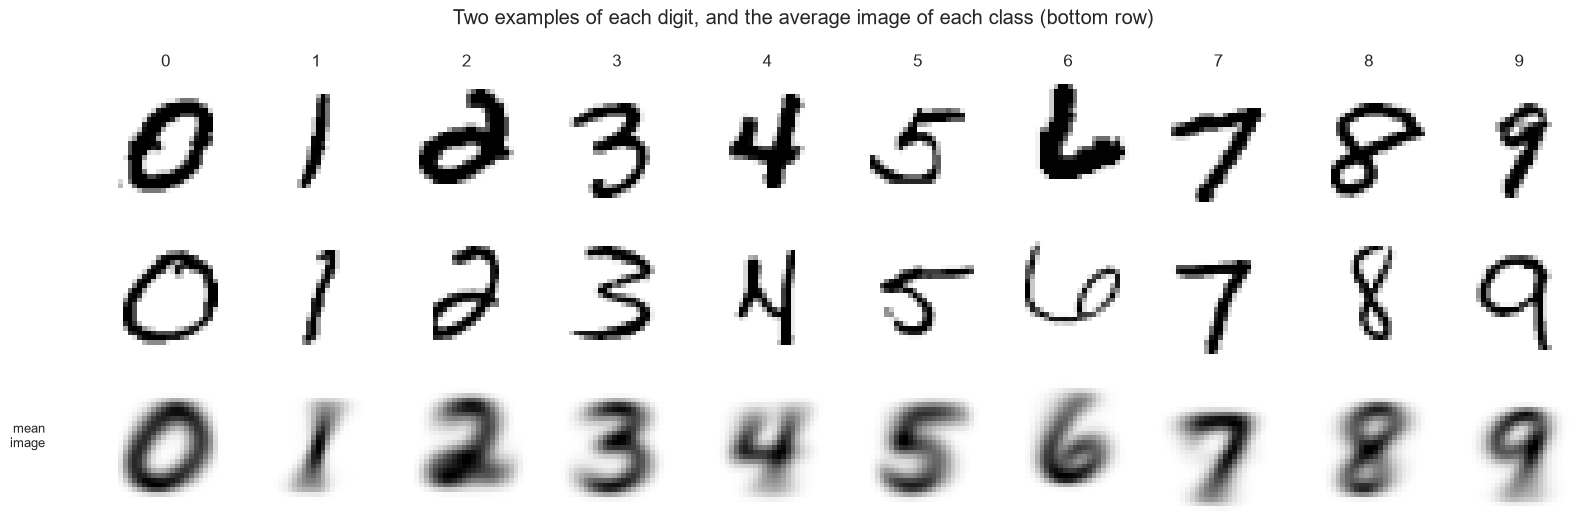

class balance (% of training images): {0: 9.8, 1: 11.2, 2: 9.9, 3: 10.3, 4: 9.7, 5: 9.1, 6: 9.8, 7: 10.4, 8: 9.8, 9: 9.9}
share of pixels that are 'ink' (>0.5): mean 13.2%, per class: {0: 17.5, 1: 7.7, 2: 15.1, 3: 14.3, 4: 12.2, 5: 13.0, 6: 13.9, 7: 11.6, 8: 15.2, 9: 12.4}


In [2]:
fig, ax = plt.subplots(3, 10, figsize=(16, 5.4))
for d in range(10):
    idx = np.where(ytr == d)[0]
    ax[0, d].imshow(Xtr[idx[0]], cmap="gray_r"); ax[1, d].imshow(Xtr[idx[1]], cmap="gray_r"); ax[2, d].imshow(Xtr[idx].mean(0), cmap="gray_r"); ax[0, d].set_title(str(d))
    for r in range(3): ax[r, d].axis("off")
ax[2, 0].text(-12, 14, "mean\nimage", fontsize=9, ha="right")
plt.suptitle("Two examples of each digit, and the average image of each class (bottom row)"); plt.tight_layout(); plt.show()
print("class balance (% of training images):", (pd.Series(ytr).value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
ink = (Xtr > 0.5).mean((1, 2)); print("share of pixels that are 'ink' (>0.5): mean %.1f%%, per class:" % (ink.mean() * 100), {d: round(float(ink[ytr == d].mean() * 100), 1) for d in range(10)})

**Reading it.** The classes are close to balanced (9.1%-11.2% each), so plain accuracy is a fair metric. Digits are centred, 28x28, dark ink on a white background in this plot. The average images show the ambiguity to expect: the mean 1 is a thin vertical line, 0 and 8 have the most ink (17.5% and 15.2% of pixels above 0.5 vs 7.7% for 1), and the means of 4/9 and 3/5/8 overlap, which is where mistakes will concentrate.

## 3. Baselines: the reference's k-NN, and a logistic regression
k-NN on the raw 784 pixels is the reference's idea. Scores on the validation set (the test set is not touched yet).

In [3]:
t = time.time(); knn = KNeighborsClassifier(3, n_jobs=8).fit(Xtr.reshape(len(Xtr), -1), ytr); acc_knn = accuracy_score(yva, knn.predict(Xva.reshape(len(Xva), -1))); t_knn = time.time() - t
t = time.time(); lr = LogisticRegression(max_iter=200).fit(Xtr.reshape(len(Xtr), -1), ytr); acc_lr = accuracy_score(yva, lr.predict(Xva.reshape(len(Xva), -1))); t_lr = time.time() - t
print("validation accuracy: k-NN (k=3, raw pixels) %.4f [%.0fs] | logistic regression %.4f [%.0fs]" % (acc_knn, t_knn, acc_lr, t_lr))

validation accuracy: k-NN (k=3, raw pixels) 0.9742 [7s] | logistic regression 0.9252 [6s]


## 4. A small CNN (PyTorch, CPU)
Two convolution blocks (32 and 64 filters, 3x3, max-pooling), dropout, one hidden layer of 128 units, 10 outputs; about 220,000 weights. Trained with Adam for 5 epochs on the 55,000 training images; the model of the best validation epoch is kept. A second copy is trained identically except that every batch is randomly **rotated (+/-15 degrees), scaled (0.9-1.1) and shifted (+/-2 pixels)**.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(1, 32, 3, padding=1), nn.Conv2d(32, 64, 3, padding=1)
        self.d1, self.f1, self.f2 = nn.Dropout(.25), nn.Linear(64 * 7 * 7, 128), nn.Linear(128, 10)
        self.d2 = nn.Dropout(.5)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2); x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.f2(self.d2(F.relu(self.f1(self.d1(x.flatten(1))))))
def affine(x, angle_deg, scale=1.0, tx=0.0, ty=0.0):
    '''apply per-sample affine transforms (tensors of shape [N] or floats) to a batch [N,1,28,28]; zero padding'''
    n = x.shape[0]; a = torch.as_tensor(angle_deg, dtype=torch.float32).expand(n) * np.pi / 180; s = torch.as_tensor(scale, dtype=torch.float32).expand(n)
    tx_, ty_ = torch.as_tensor(tx, dtype=torch.float32).expand(n) * 2 / 28, torch.as_tensor(ty, dtype=torch.float32).expand(n) * 2 / 28
    th = torch.zeros(n, 2, 3); th[:, 0, 0] = torch.cos(a) / s; th[:, 0, 1] = -torch.sin(a) / s; th[:, 1, 0] = torch.sin(a) / s; th[:, 1, 1] = torch.cos(a) / s; th[:, 0, 2] = tx_; th[:, 1, 2] = ty_
    return F.grid_sample(x, F.affine_grid(th, x.shape, align_corners=False), align_corners=False, padding_mode="zeros")
def augment(x):
    n = x.shape[0]; return affine(x, (torch.rand(n) - .5) * 30, 0.9 + 0.2 * torch.rand(n), (torch.rand(n) - .5) * 4, (torch.rand(n) - .5) * 4)
T = lambda a: torch.from_numpy(a).unsqueeze(1)
Ttr, Tva, Tte = T(Xtr), T(Xva), T(Xte); Ytr, Yva, Yte = map(torch.from_numpy, (ytr, yva, yte))
def predict(m, X, bs=2000):
    m.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(F.softmax(m(X[i:i + bs]), 1))
    return torch.cat(out)
def train(aug, epochs=5, seed=0):
    torch.manual_seed(seed); m = CNN(); opt = torch.optim.Adam(m.parameters(), 1e-3); best, best_state, hist = 0, None, []
    for ep in range(epochs):
        m.train(); p = torch.randperm(len(Ttr)); t0 = time.time()
        for i in range(0, len(p), 128):
            b = p[i:i + 128]; xb = Ttr[b]; xb = augment(xb) if aug else xb
            loss = F.cross_entropy(m(xb), Ytr[b]); opt.zero_grad(); loss.backward(); opt.step()
        acc = (predict(m, Tva).argmax(1) == Yva).float().mean().item(); hist.append(acc)
        if acc > best: best, best_state = acc, {k: v.clone() for k, v in m.state_dict().items()}
        print(f"  {'augmented' if aug else 'plain'} epoch {ep+1}: validation accuracy {acc:.4f} ({time.time()-t0:.0f}s)")
    m.load_state_dict(best_state); return m, hist
cnn, h_plain = train(False)
cnn_aug, h_aug = train(True)

  plain epoch 1: validation accuracy 0.9742 (18s)


  plain epoch 2: validation accuracy 0.9838 (19s)


  plain epoch 3: validation accuracy 0.9866 (19s)


  plain epoch 4: validation accuracy 0.9894 (22s)


  plain epoch 5: validation accuracy 0.9904 (19s)


  augmented epoch 1: validation accuracy 0.9800 (18s)


  augmented epoch 2: validation accuracy 0.9834 (19s)


  augmented epoch 3: validation accuracy 0.9892 (22s)


  augmented epoch 4: validation accuracy 0.9910 (24s)


  augmented epoch 5: validation accuracy 0.9890 (21s)


**Reading it.** Validation accuracy of the plain CNN rises from 97.4% after one epoch to 99.0% after five; the augmented CNN reaches 99.1% at epoch 4 (99.0% at epoch 5). Both are still improving slowly, so more epochs could add a little; I stopped at five to keep CPU training near two minutes per model. On the 5,000-image validation set, differences below about 0.3 points are noise. For comparison k-NN on raw pixels scored 97.4% and logistic regression 92.5% on the same validation set.

## 5. Final test-set scores (the test set is used here for the first time)

In [5]:
P = {"k-NN raw pixels": knn.predict_proba(Xte.reshape(len(Xte), -1)), "logistic regression": lr.predict_proba(Xte.reshape(len(Xte), -1)), "CNN": predict(cnn, Tte).numpy(), "CNN + augmentation": predict(cnn_aug, Tte).numpy()}
test_acc = {k: accuracy_score(yte, v.argmax(1)) for k, v in P.items()}
n_err = {k: int((v.argmax(1) != yte).sum()) for k, v in P.items()}
se = {k: np.sqrt(a * (1 - a) / len(yte)) for k, a in test_acc.items()}
print(pd.DataFrame({"test_accuracy": test_acc, "errors_out_of_10000": n_err, "95%_half_width": {k: 1.96 * v for k, v in se.items()}}).round(4).to_string())

                     test_accuracy  errors_out_of_10000  95%_half_width
k-NN raw pixels             0.9699                  301          0.0033
logistic regression         0.9249                  751          0.0052
CNN                         0.9909                   91          0.0019
CNN + augmentation          0.9896                  104          0.0020


**Reading it (10,000 test images; the interval is the +/-95% half-width).**
* **CNN 99.09% (91 errors), CNN + augmentation 98.96% (104 errors):** statistically the same (the intervals are +/-0.2 points).
* **k-NN on raw pixels (the reference's idea) 96.99% (301 errors)**: about 3.3 times as many errors as the CNN.
* Logistic regression 92.49% (751 errors).
* The ranking CNN > k-NN > logistic regression is clear. Note that the reference's own data are different (32x32 binary images, a few thousand), so its accuracy figure cannot be compared with these.

## 6. Study the mistakes of the CNN

most frequent confusions (true -> predicted: count): ['7->2: 8', '9->7: 5', '9->5: 4', '9->4: 4', '8->9: 4', '5->3: 4']


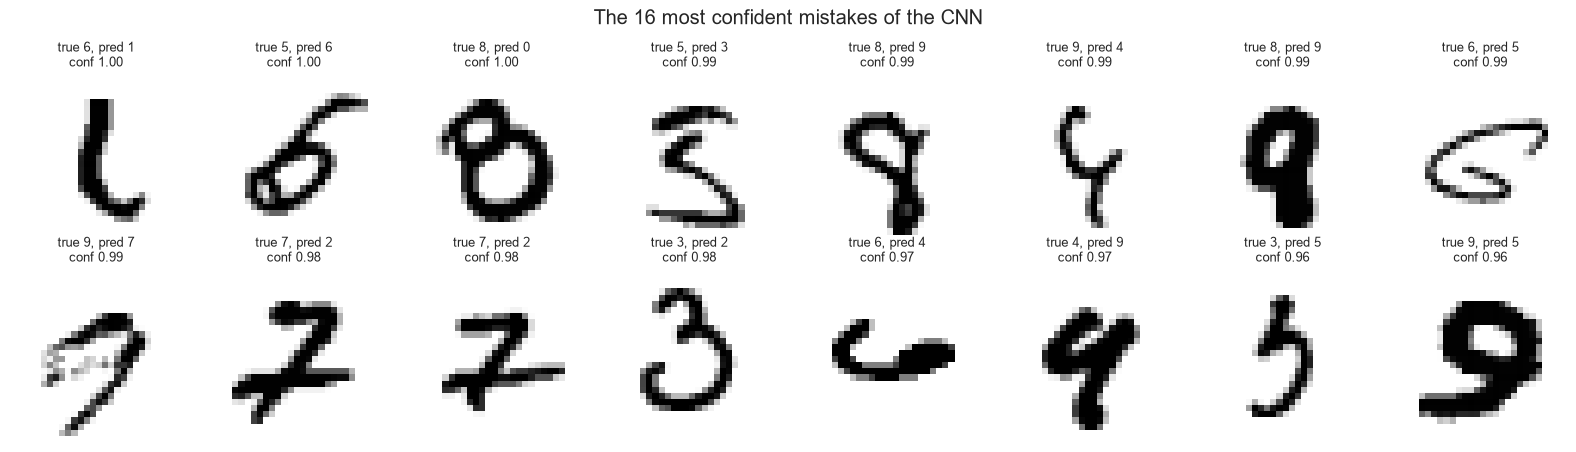

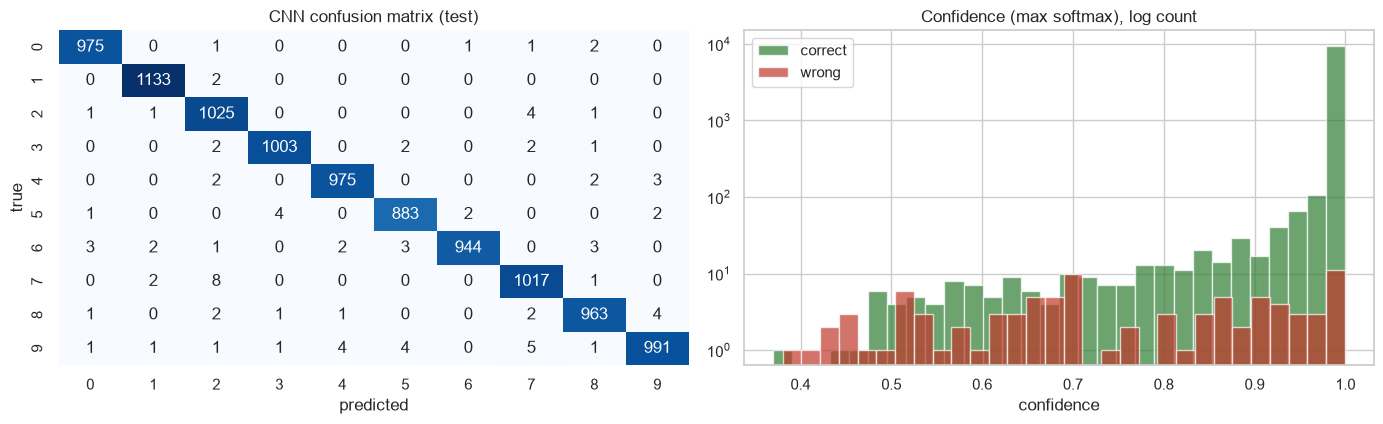

In [6]:
p = P["CNN"]; pred = p.argmax(1); wrong = np.where(pred != yte)[0]
cm = confusion_matrix(yte, pred); np.fill_diagonal(cm, 0)
pairs = sorted([(cm[i, j], i, j) for i in range(10) for j in range(10) if i != j], reverse=True)[:6]
print("most frequent confusions (true -> predicted: count):", [f"{i}->{j}: {c}" for c, i, j in pairs])
conf_wrong = p.max(1)[wrong]; order = wrong[np.argsort(-conf_wrong)][:16]
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for a, i in zip(ax.ravel(), order): a.imshow(Xte[i], cmap="gray_r"); a.set_title(f"true {yte[i]}, pred {pred[i]}\nconf {p[i].max():.2f}", fontsize=9); a.axis("off")
plt.suptitle("The 16 most confident mistakes of the CNN"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0]); ax[0].set_title("CNN confusion matrix (test)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
ax[1].hist(p.max(1)[pred == yte], bins=30, alpha=.7, label="correct", color="#2e7d32", log=True); ax[1].hist(p.max(1)[wrong], bins=30, alpha=.7, label="wrong", color="#c0392b", log=True); ax[1].legend(); ax[1].set_title("Confidence (max softmax), log count"); ax[1].set_xlabel("confidence")
plt.tight_layout(); plt.show()

**Reading it.** Of the CNN's 91 errors, the most frequent confusions are 7 mistaken for 2 (8 cases), then 9 for 7, 9 for 5, 9 for 4, 8 for 9 and 5 for 3 (4-5 cases each); 9 is the most error-prone digit. Wrong answers are generally less confident than right ones (right panel: almost all correct predictions sit at confidence near 1, wrong ones are spread from 0.4 to 1), but a few wrong answers are made with confidence above 0.9, so confidence is informative, not infallible. The figure above shows the 16 most confident mistakes; some of these may be ambiguous or mislabelled digits (I have not checked the labels one by one).

## 7. Can the model say "I am not sure"? Calibration and abstaining
Expected calibration error (ECE) compares confidence with accuracy in 10 confidence bins. The accuracy-coverage curve shows what happens if the model refuses to answer when confidence is below a threshold.

ECE: CNN 0.0025 | CNN+aug 0.0020 | logistic regression 0.0027 | k-NN 0.0125


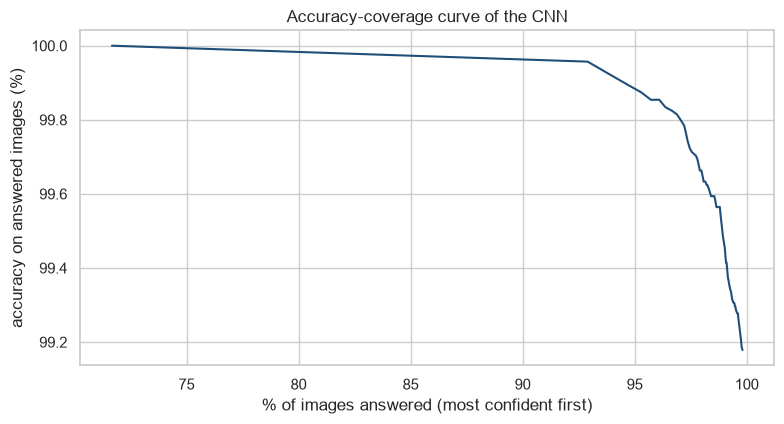

threshold 0.900: answers 97.34% of images, accuracy on them 99.753%
threshold 0.990: answers 93.38% of images, accuracy on them 99.946%
threshold 0.999: answers 85.42% of images, accuracy on them 99.988%


In [7]:
def ece(p, y, bins=10):
    conf, ok = p.max(1), (p.argmax(1) == y); edges = np.linspace(0, 1, bins + 1); e = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return e
print("ECE: CNN %.4f | CNN+aug %.4f | logistic regression %.4f | k-NN %.4f" % tuple(ece(P[k], yte) for k in ["CNN", "CNN + augmentation", "logistic regression", "k-NN raw pixels"]))
conf = P["CNN"].max(1); ok = (P["CNN"].argmax(1) == yte); ths = np.linspace(.5, .9999, 60)
cov = [(conf >= t).mean() for t in ths]; acc = [ok[conf >= t].mean() for t in ths]
fig, ax = plt.subplots(figsize=(8, 4.4)); ax.plot(np.array(cov) * 100, np.array(acc) * 100, color="#1f4e79"); ax.set_xlabel("% of images answered (most confident first)"); ax.set_ylabel("accuracy on answered images (%)"); ax.set_title("Accuracy-coverage curve of the CNN"); plt.tight_layout(); plt.show()
for t in (0.9, 0.99, 0.999): print("threshold %.3f: answers %.2f%% of images, accuracy on them %.3f%%" % (t, (conf >= t).mean() * 100, ok[conf >= t].mean() * 100))

**Reading it.**
* **The CNN is well calibrated:** ECE 0.0025 (its stated confidence matches its accuracy within a quarter of a percentage point). The k-NN, whose "confidence" is the share of the 3 neighbours that agree, is five times worse (0.0125).
* **A "reject" option is cheap:** answering only when confidence is at least 0.99 means answering 93.4% of the images with 99.95% accuracy; at 0.999, 85.4% of images with 99.99% accuracy. For a form-reading system, sending the remaining 6-15% to a human buys a large reduction in errors.

## 8. Robustness: does it still read digits that are rotated, shifted, noisy, thicker, thinner or inverted?
The same 10,000 test images are transformed and re-scored. All of these are changes a real user might introduce (a tilted hand, an off-centre drawing, a thick marker, a dark-on-light photo).

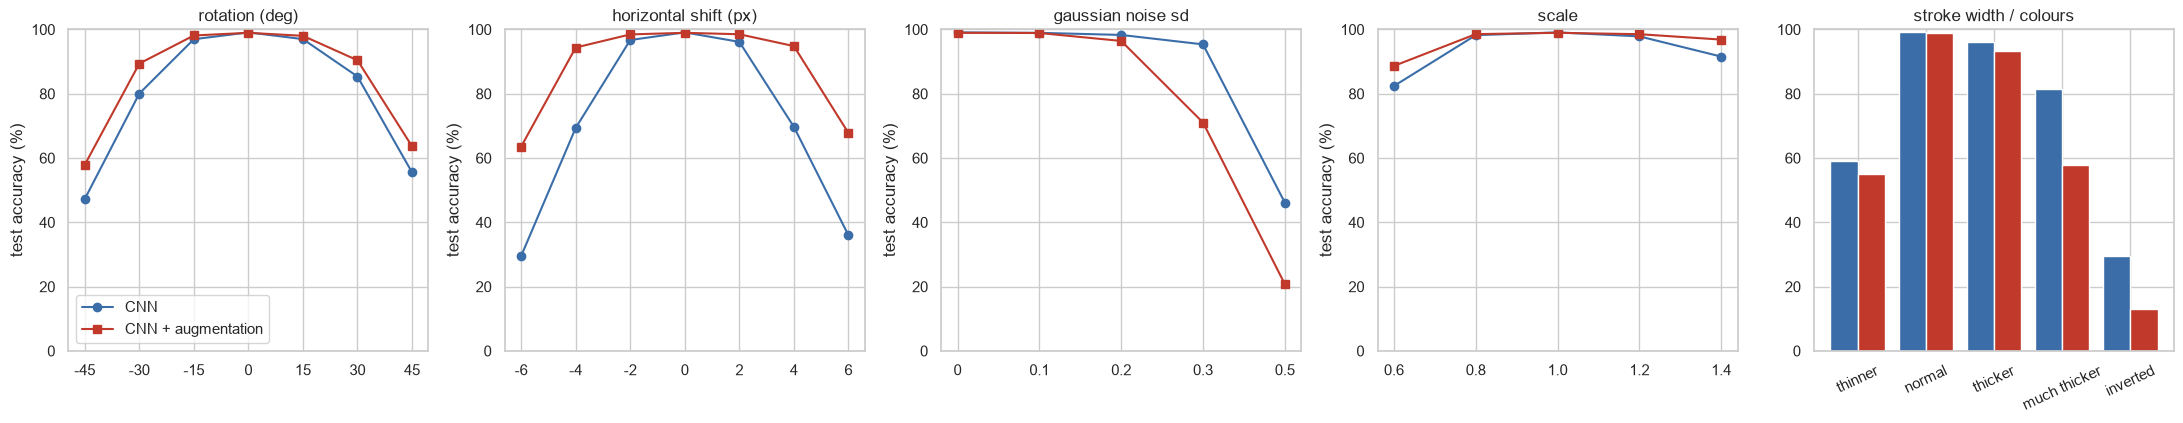

                 test        level  CNN  CNN + augmentation
       rotation (deg)          -45 47.2                57.9
       rotation (deg)          -30 80.1                89.4
       rotation (deg)          -15 97.0                98.1
       rotation (deg)            0 99.1                99.0
       rotation (deg)           15 97.0                98.0
       rotation (deg)           30 85.4                90.4
       rotation (deg)           45 55.5                63.6
horizontal shift (px)           -6 29.5                63.6
horizontal shift (px)           -4 69.4                94.4
horizontal shift (px)           -2 96.7                98.5
horizontal shift (px)            0 99.1                99.0
horizontal shift (px)            2 96.1                98.5
horizontal shift (px)            4 69.7                94.8
horizontal shift (px)            6 36.0                67.8
    gaussian noise sd            0 99.1                99.0
    gaussian noise sd          0.1 98.9 

In [8]:
def acc_of(m, X): return (predict(m, X).argmax(1) == Yte).float().mean().item() * 100
def dilate(x, k=3): return F.max_pool2d(x, k, 1, k // 2)
def erode(x, k=3): return -F.max_pool2d(-x, k, 1, k // 2)
tests = {}
for a in (-45, -30, -15, 0, 15, 30, 45): tests[("rotation (deg)", a)] = affine(Tte, float(a))
for s in (-6, -4, -2, 0, 2, 4, 6): tests[("horizontal shift (px)", s)] = affine(Tte, 0.0, 1.0, float(s), 0.0)
for sg in (0, .1, .2, .3, .5): tests[("gaussian noise sd", sg)] = (Tte + sg * torch.randn(Tte.shape, generator=torch.Generator().manual_seed(1))).clamp(0, 1)
for sc in (0.6, 0.8, 1.0, 1.2, 1.4): tests[("scale", sc)] = affine(Tte, 0.0, float(sc))
tests[("stroke", "thinner")] = erode(Tte); tests[("stroke", "normal")] = Tte; tests[("stroke", "thicker")] = dilate(Tte); tests[("stroke", "much thicker")] = dilate(dilate(Tte))
tests[("colours", "inverted")] = 1 - Tte
rob = pd.DataFrame([[k[0], str(k[1]), acc_of(cnn, v), acc_of(cnn_aug, v)] for k, v in tests.items()], columns=["test", "level", "CNN", "CNN + augmentation"])
fam = ["rotation (deg)", "horizontal shift (px)", "gaussian noise sd", "scale"]
fig, ax = plt.subplots(1, 5, figsize=(22, 4.4))
for a, f in zip(ax, fam):
    d = rob[rob.test == f]; a.plot(d.level, d.CNN, "o-", color="#3b6ea8", label="CNN"); a.plot(d.level, d["CNN + augmentation"], "s-", color="#c0392b", label="CNN + augmentation"); a.set_title(f); a.set_ylim(0, 100); a.set_ylabel("test accuracy (%)")
ax[0].legend()
d = rob[rob.test.isin(["stroke", "colours"])]; x = np.arange(len(d)); ax[4].bar(x - .2, d.CNN, .4, color="#3b6ea8"); ax[4].bar(x + .2, d["CNN + augmentation"], .4, color="#c0392b"); ax[4].set_xticks(x); ax[4].set_xticklabels(d.level, rotation=25); ax[4].set_title("stroke width / colours"); ax[4].set_ylim(0, 100)
plt.tight_layout(); plt.show()
print(rob.round(1).to_string(index=False))

**Reading it (test accuracy % of the same 10,000 images after each change).**
* **Rotation:** both models are fine up to about 15 degrees (97-98%) and fall steeply beyond that: at 30 degrees the plain CNN gets 80-85%, at 45 degrees 47-56%. Augmentation helps (e.g. 63.6% vs 55.5% at +45 degrees).
* **Shift:** the plain CNN loses 30 points at 4 pixels (69%) and falls to 30-36% at 6 pixels (the digit is then partly out of the frame), while the augmented model holds 94% at 4 pixels. **Training only on centred digits makes a model brittle to position**: a drawing pad where users do not centre their digit would see this.
* **Noise:** the plain CNN tolerates noise (95.4% at sd 0.3); **the augmented model is worse (71.1%)**.
* **Stroke width:** both are hurt by thinner strokes (59% / 55%), and the augmented model is much worse for very thick strokes (57.9% vs 81.6%).
* **Inverted colours (white ink on black): 29.6% / 13.1%**, that is no better than guessing for the augmented model (random guessing would give 10%, and 13.1% is close to that): the model learned "dark ink on light background" as part of the task.
* So augmentation is not a free improvement: it fixed the geometric weaknesses and created a different one (noise and stroke width). I did not test why; a possible reason is that interpolating images during rotation/shift smooths the training digits, but that is a hypothesis, not a finding. The combination of augmentations should follow the intended use.

## 9. Save

In [9]:
torch.save(cnn.state_dict(), "model/mnist_cnn_plain.pt"); torch.save(cnn_aug.state_dict(), "model/mnist_cnn_aug.pt")
joblib.dump(lr, "model/mnist_logreg.joblib")
sample = np.random.RandomState(1).choice(len(Xte), 40, replace=False); np.save("model/test_samples.npy", np.c_[Xte[sample].reshape(40, -1), yte[sample]].astype(np.float32))
json.dump({"test_accuracy": test_acc, "errors": n_err, "ece_cnn": float(ece(P["CNN"], yte)), "robustness": rob.round(2).to_dict("records")}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['meta.json', 'mnist_cnn_aug.pt', 'mnist_cnn_plain.pt', 'mnist_logreg.joblib', 'test_samples.npy']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | 32x32 binary text images (thousands) | MNIST: 55,000 train / 5,000 validation / 10,000 test |
| Model | k-NN on flattened pixels | k-NN (same idea), logistic regression, CNN, CNN + augmentation |
| Test accuracy | not reported as one comparable number | k-NN 96.99%, logistic 92.49%, **CNN 99.09%**, CNN+aug 98.96% |
| Confidence | none | CNN calibrated (ECE 0.0025); 93% coverage at 99.95% accuracy |
| Robustness | not tested | rotation, shift, scale, noise, stroke width, inversion: big drops outside the training conditions |

**What I learned.** (1) The k-NN idea works (97%) but a CNN makes about 3 times fewer errors with one fast epoch loop. (2) A near-perfect benchmark score says little about messy input: shift by 4 pixels cost the plain CNN 30 points. (3) Augmentation fixes what it simulates and can hurt elsewhere. (4) A calibrated confidence enables a "refer to a human" rule.

**Limits.** MNIST digits are centred, size-normalised and written by US census workers and students; photos, other scripts or other pens will differ. Only 5 epochs, one seed per model (so tiny differences like 99.09 vs 98.96 are not meaningful). **Next step:** train with milder, mixed augmentations plus noise and stroke jitter, and evaluate on digits drawn by real users.